# Pergunta 5 — Educação especial no Brasil

**O avanço da inclusão foi semelhante entre as regiões? Quais estados mais contribuíram para o crescimento das matrículas?**

A análise usa as Sinopses Estatísticas da Educação Básica do INEP de **2015, 2020 e 2025**. Primeiro, comparamos a inclusão nas cinco regiões com o Brasil. Depois, analisamos a contribuição de cada estado para o aumento do número de matrículas.

**Fonte:** INEP, *Sinopses Estatísticas da Educação Básica* (2015, 2020 e 2025).

## 1. Leitura dos dados

A planilha tem uma linha por estado e por ano, além do total nacional. Separamos o Brasil dos estados para não contar as mesmas matrículas duas vezes.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

arquivo = Path('base_limpa_pergunta5_inep_2015_2020_2025.xlsx')

dados = pd.read_excel(arquivo, sheet_name='Base limpa', header=3)

dados['ano'] = dados['ano'].astype(int)
for coluna in ['matriculas_total', 'matriculas_classes_comuns', 'matriculas_classes_exclusivas']:
    dados[coluna] = pd.to_numeric(dados[coluna])

# Calculamos a inclusão a partir do número de matrículas, sem usar porcentagens prontas.
dados['inclusao_pct'] = 100 * dados['matriculas_classes_comuns'] / dados['matriculas_total']
estados = dados[dados['nivel'] == 'UF'].copy()
brasil = dados[dados['nivel'] == 'Brasil'].copy().sort_values('ano')

# Conferimos as 27 UFs e os totais divulgados para o Brasil.
assert len(estados) == 81 and len(brasil) == 3
assert estados.groupby('ano')['uf'].nunique().eq(27).all()
assert (dados['matriculas_classes_comuns'] + dados['matriculas_classes_exclusivas'] == dados['matriculas_total']).all()
assert (estados.groupby('ano')['matriculas_total'].sum().sort_index().to_numpy() == brasil['matriculas_total'].to_numpy()).all()

print('Dados conferidos: 27 estados e três anos.')
display(brasil[['ano', 'matriculas_total', 'inclusao_pct']].round(2).reset_index(drop=True))

Dados conferidos: 27 estados e três anos.


,ano,matriculas_total,inclusao_pct
0,2015,930683,80.69
1,2020,1308900,88.08
2,2025,2458159,93.48


## 2. Inclusão em classes comuns por região

O gráfico reúne as **cinco regiões brasileiras** e a linha nacional. Para cada região, calculamos o percentual a partir da soma das matrículas em classes comuns dividida pelo total de matrículas da educação especial na região. Assim, cada estado participa conforme o número de matrículas que possui; não usamos uma média simples dos percentuais estaduais.

A comparação considera três anos: **2015, 2020 e 2025**. As linhas ligam esses pontos, sem estimar os anos intermediários.

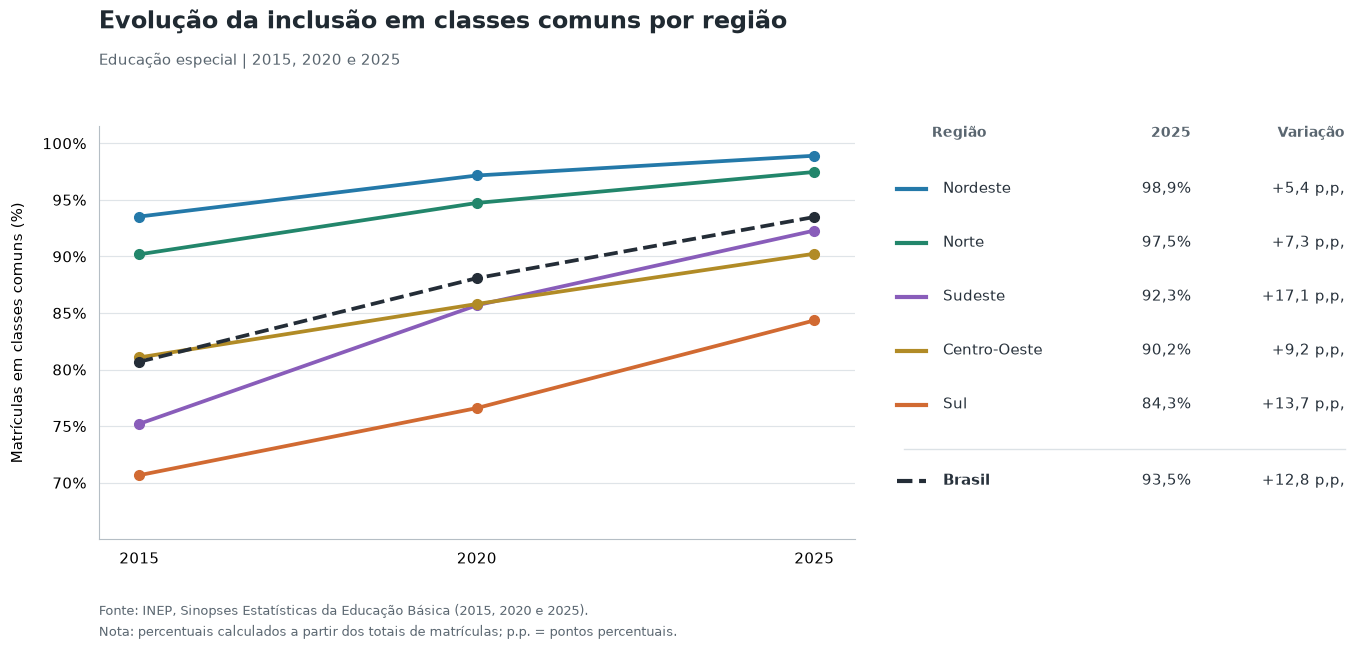

In [3]:
# Somamos as matrículas por região antes de calcular o percentual de inclusão.
resumo_regioes = (
    estados.groupby(['regiao', 'ano'], as_index=False)[
        ['matriculas_total', 'matriculas_classes_comuns']
    ].sum()
)
resumo_regioes['inclusao_pct'] = (
    100 * resumo_regioes['matriculas_classes_comuns']
    / resumo_regioes['matriculas_total']
)

anos = [2015, 2020, 2025]
cores = {
    'Norte': '#22866B',
    'Nordeste': '#2479A9',
    'Sudeste': '#895DBA',
    'Sul': '#D16A32',
    'Centro-Oeste': '#B18B26',
    'Brasil': '#242D37'
}

figura, grafico = plt.subplots(figsize=(14, 7))
figura.subplots_adjust(left=0.09, right=0.63, top=0.78, bottom=0.19)

# Uma única linha por região facilita a comparação da mudança ao longo do tempo.
ordem = ['Nordeste', 'Norte', 'Sudeste', 'Centro-Oeste', 'Sul']
for regiao in ordem:
    serie = resumo_regioes[resumo_regioes['regiao'] == regiao].sort_values('ano')
    grafico.plot(
        serie['ano'], serie['inclusao_pct'],
        color=cores[regiao], marker='o', markersize=7,
        linewidth=2.7, label=regiao
    )

# O Brasil funciona como referência; é o percentual nacional calculado pelo total de matrículas.
grafico.plot(
    brasil['ano'], brasil['inclusao_pct'],
    color=cores['Brasil'], linestyle='--',
    marker='o', markersize=7, linewidth=2.7, label='Brasil'
)

grafico.set_xlim(2014.4, 2025.6)
grafico.set_ylim(65, 101.5)
grafico.set_xticks(anos)
grafico.set_yticks([70, 75, 80, 85, 90, 95, 100])
grafico.set_yticklabels(['70%', '75%', '80%', '85%', '90%', '95%', '100%'])
grafico.grid(axis='y', color='#dfe4e8', linewidth=0.85)
grafico.set_axisbelow(True)
grafico.spines[['top', 'right']].set_visible(False)
grafico.spines[['left', 'bottom']].set_color('#b5bec5')
grafico.tick_params(axis='both', labelsize=11, length=0, pad=9)
grafico.set_ylabel('Matrículas em classes comuns (%)', fontsize=11, labelpad=12)

figura.text(0.09, 0.92, 'Evolução da inclusão em classes comuns por região',
            fontsize=17, weight='bold', color='#202a32')
figura.text(0.09, 0.868, 'Educação especial | 2015, 2020 e 2025',
            fontsize=11, color='#5a6670')

# Resumo lateral: valor de 2025 e variação desde 2015, em pontos percentuais.
figura.text(0.685, 0.765, 'Região', fontsize=10, color='#5a6670', weight='bold')
figura.text(0.87, 0.765, '2025', fontsize=10, color='#5a6670', weight='bold', ha='right')
figura.text(0.98, 0.765, 'Variação', fontsize=10, color='#5a6670', weight='bold', ha='right')

def escrever_resumo(nome, valores, altura):
    valor_2015 = valores.loc[2015]
    valor_2025 = valores.loc[2025]
    aumento = valor_2025 - valor_2015
    linha = '--' if nome == 'Brasil' else '-'
    figura.lines.append(plt.Line2D([0.66, 0.681], [altura + 0.005, altura + 0.005],
                                   color=cores[nome], linewidth=3,
                                   linestyle=linha, transform=figura.transFigure))
    figura.text(0.693, altura, nome, fontsize=11, color='#28323c',
                weight='bold' if nome == 'Brasil' else 'normal')
    figura.text(0.87, altura, f'{valor_2025:.1f}%'.replace('.', ','),
                fontsize=11, ha='right', color='#28323c')
    figura.text(0.98, altura, f'+{aumento:.1f} p.p.'.replace('.', ','),
                fontsize=11, ha='right', color='#28323c')

for regiao, altura in zip(ordem, [0.685, 0.608, 0.531, 0.454, 0.377]):
    percentual = resumo_regioes[resumo_regioes['regiao'] == regiao].set_index('ano')['inclusao_pct']
    escrever_resumo(regiao, percentual, altura)

figura.lines.append(plt.Line2D([0.665, 0.98], [0.319, 0.319],
                               color='#dce2e6', linewidth=1,
                               transform=figura.transFigure))
escrever_resumo('Brasil', brasil.set_index('ano')['inclusao_pct'], 0.268)

figura.text(0.09, 0.082,
            'Fonte: INEP, Sinopses Estatísticas da Educação Básica (2015, 2020 e 2025).',
            fontsize=9.5, color='#5a6670')
figura.text(0.09, 0.052,
            'Nota: percentuais calculados a partir dos totais de matrículas; p.p. = pontos percentuais.',
            fontsize=9.3, color='#5a6670')

plt.savefig('inclusao_por_regiao.png', dpi=190, bbox_inches='tight', facecolor='white')
plt.show()

## 3. Quais estados mais contribuíram para o aumento das matrículas?

Aqui comparamos o **número de matrículas** de 2015 e 2025. A contribuição de cada estado é sua parte no aumento total do Brasil. Isso não é a mesma coisa que a taxa de crescimento estadual.

,uf,matriculas_2015,matriculas_2020,matriculas_2025,aumento_matriculas,contribuicao_pct
0,São Paulo,167251,213061,373454,206203,13.50
1,Bahia,62645,102286,219850,157205,10.29
2,Ceará,41341,66741,160556,119215,7.80
3,Minas Gerais,111014,145607,227069,116055,7.60
4,Rio de Janeiro,54562,79329,154308,99746,6.53
5,Paraná,81345,104280,165666,84321,5.52
6,Pernambuco,31207,48573,112445,81238,5.32
7,Pará,31601,52779,104842,73241,4.79
8,Santa Catarina,27438,40913,98708,71270,4.67
9,Rio Grande do Sul,76402,96106,143069,66667,4.36


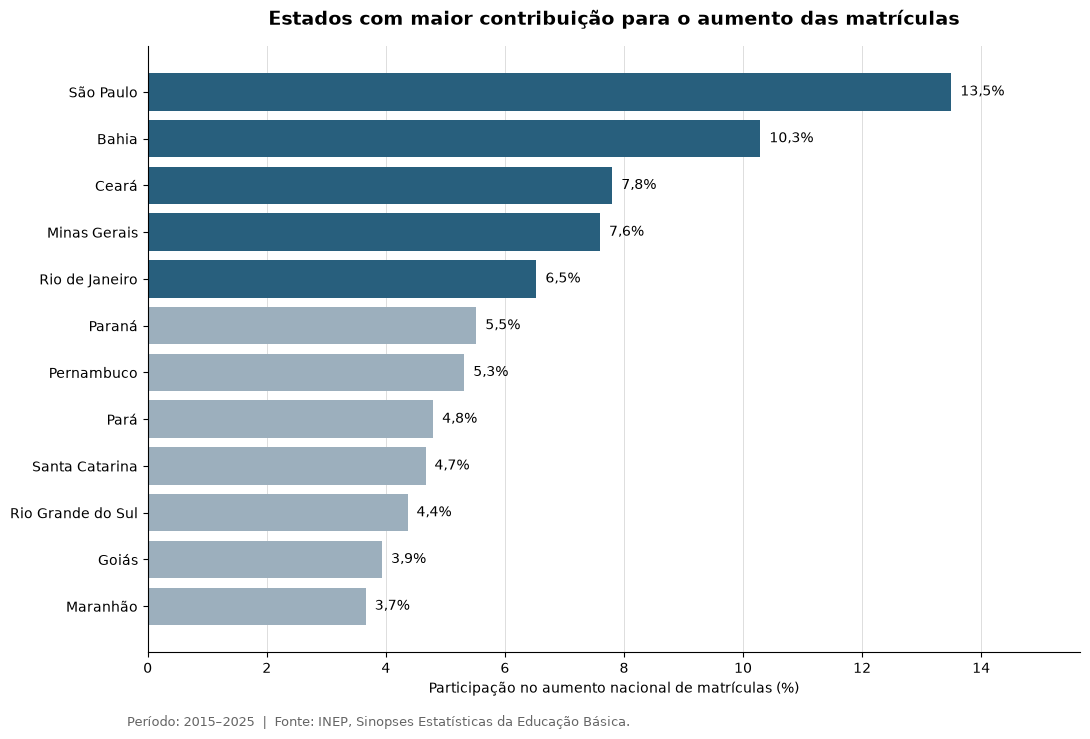

In [4]:
# Juntamos os três anos em uma linha para cada estado.
comparacao = estados.pivot(index=['regiao', 'uf'], columns='ano', values='matriculas_total').reset_index()
comparacao.columns.name = None
comparacao = comparacao.rename(columns={
    2015: 'matriculas_2015',
    2020: 'matriculas_2020',
    2025: 'matriculas_2025'
})

comparacao['aumento_matriculas'] = comparacao['matriculas_2025'] - comparacao['matriculas_2015']
comparacao['crescimento_pct'] = 100 * comparacao['aumento_matriculas'] / comparacao['matriculas_2015']

matriculas_brasil = brasil.set_index('ano')['matriculas_total']
aumento_brasil = matriculas_brasil.loc[2025] - matriculas_brasil.loc[2015]

# As contribuições dos 27 estados devem somar 100%.
comparacao['contribuicao_pct'] = 100 * comparacao['aumento_matriculas'] / aumento_brasil
comparacao = comparacao.sort_values('contribuicao_pct', ascending=False)
assert comparacao['aumento_matriculas'].sum() == aumento_brasil
assert abs(comparacao['contribuicao_pct'].sum() - 100) < 1e-8

colunas_resumo = ['uf', 'matriculas_2015', 'matriculas_2020',
                  'matriculas_2025', 'aumento_matriculas', 'contribuicao_pct']
display(comparacao[colunas_resumo].head(12).round(2).reset_index(drop=True))

principais_estados = comparacao.head(12).sort_values('contribuicao_pct')
destaques = set(comparacao.head(5)['uf'])
cores_barras = ['#285f7d' if nome in destaques else '#9cafbd'
                for nome in principais_estados['uf']]

figura, grafico = plt.subplots(figsize=(11, 7.5))
grafico.barh(principais_estados['uf'], principais_estados['contribuicao_pct'], color=cores_barras)

for posicao, valor in enumerate(principais_estados['contribuicao_pct']):
    grafico.text(valor + 0.15, posicao, f'{valor:.1f}%'.replace('.', ','),
                 va='center', fontsize=10)

grafico.set_xlim(0, principais_estados['contribuicao_pct'].max() * 1.16)
grafico.set_title('Estados com maior contribuição para o aumento das matrículas',
                   fontsize=14, fontweight='bold', pad=15)
grafico.set_xlabel('Participação no aumento nacional de matrículas (%)')
grafico.grid(axis='x', color='#dddddd', linewidth=0.7)
grafico.set_axisbelow(True)
grafico.spines[['top', 'right']].set_visible(False)
figura.text(0.12, 0.025, 'Período: 2015–2025  |  Fonte: INEP, Sinopses Estatísticas da Educação Básica.',
            fontsize=9, color='#666666')
figura.tight_layout(rect=[0, 0.045, 1, 1])

plt.savefig('contribuicao_estadual.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Leitura dos resultados

A proporção de matrículas em classes comuns aumentou em **todas as regiões** entre 2015 e 2025. O **Nordeste** já tinha um percentual alto em 2015 (93,5%) e chegou a **98,9%** em 2025. O **Sudeste** apresentou o maior avanço, passando de **75,2% para 92,3%**. O **Sul** também cresceu, mas terminou o período com **84,3%**, abaixo do Brasil (**93,5%**).

O número de matrículas da educação especial no país passou de **930,7 mil para 2,46 milhões**. No segundo gráfico, **São Paulo, Bahia, Ceará, Minas Gerais e Rio de Janeiro** foram os cinco estados que mais contribuíram para esse aumento, somando cerca de **45,7%** do crescimento nacional.

Os gráficos mostram aspectos diferentes: o primeiro compara o percentual de matrículas em classes comuns, enquanto o segundo mostra onde ocorreu o maior aumento no número de matrículas. **Os dados não medem a qualidade do atendimento.** Além disso, com três anos observados não é possível descrever todas as mudanças que ocorreram entre eles.